# Predicting Economic Opportunity from Education and Work Characteristics
### Traditional Machine Learning vs. Deep Learning on the UCI Adult (Census Income) Dataset

**Mission link (Ascend Rwanda):** the mission is to widen access to literacy, digital and financial skills for people whose background limits their economic opportunity. Before designing an intervention, we need evidence on *which* factors (education level, occupation, hours, household role) are most strongly associated with crossing an income threshold, and whether a model can identify people at risk of remaining in low-income outcomes. This notebook builds and compares classical ML and deep learning classifiers for that task.

| Item | Link |
|---|---|
| GitHub repository | *add link* |
| Google Drive (raw data + saved models) | *add link* |
| Video presentation | *add link* |

**Notebook structure**
1. Setup & reproducibility
2. Data loading
3. Exploratory data analysis
4. Cleaning & preprocessing
5. Feature engineering
6. Train / validation / test split and preprocessing pipelines
7. Evaluation & logging utilities (TensorBoard)
8. Traditional ML experiments (E1–E7)
9. Deep learning experiments with `tf.data` (E8–E13)
10. Experiment table
11. Final test-set evaluation (confusion matrices, ROC, PR, learning curves)
12. Error analysis by subgroup
13. Saving the best models
14. Conclusions

## 1. Setup & reproducibility
All dependencies are listed in `requirements.txt`. On Google Colab, run the install cell below once. A single global seed (`SEED = 42`) is applied to Python, NumPy and TensorFlow so that every run in the experiment table can be reproduced.

In [2]:
# Uncomment on a fresh Colab runtime
# !pip install -q -r requirements.txt

In [3]:
import os, random, zipfile, io, json, time, warnings, urllib.request
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_seeds()

OUT_DIR = "outputs"; FIG_DIR = f"{OUT_DIR}/figures"; MODEL_DIR = f"{OUT_DIR}/models"; LOG_DIR = "logs"
for d in [OUT_DIR, FIG_DIR, MODEL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
print("TensorFlow", tf.__version__, "| scikit-learn", __import__("sklearn").__version__)

TensorFlow 2.21.0 | scikit-learn 1.6.1


## 2. Data loading
The dataset is the **Adult (Census Income)** dataset from the UCI Machine Learning Repository, extracted by Becker and Kohavi from the 1994 US Census database. It contains **48,842 records** (32,561 in `adult.data` and 16,281 in `adult.test`), 14 attributes, and a binary target: whether annual income exceeds \$50K.

The raw zip is **not** stored in GitHub. The loader looks for `adult.zip` locally (e.g. after downloading it from the project's Google Drive folder) and otherwise downloads it from UCI.

In [4]:
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
           "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
           "hours_per_week", "native_country", "income"]
UCI_URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"

def find_or_download_zip():
    for p in ["adult.zip", "data/adult.zip", "/content/adult.zip", "/content/drive/MyDrive/adult.zip"]:
        if os.path.exists(p):
            return p
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(UCI_URL, "data/adult.zip")
    return "data/adult.zip"

def load_adult(zip_path):
    # Read adult.data and adult.test straight from the zip archive.
    with zipfile.ZipFile(zip_path) as z:
        train = pd.read_csv(z.open("adult.data"), header=None, names=COLUMNS,
                            skipinitialspace=True)
        test = pd.read_csv(z.open("adult.test"), header=None, names=COLUMNS,
                           skipinitialspace=True, skiprows=1)  # first line is a comment
    return train, test

ZIP_PATH = find_or_download_zip()
raw_train, raw_test = load_adult(ZIP_PATH)
print("adult.data:", raw_train.shape, "| adult.test:", raw_test.shape,
      "| total rows:", len(raw_train) + len(raw_test))
raw_train.head()

adult.data: (32561, 15) | adult.test: (16281, 15) | total rows: 48842


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Exploratory data analysis
We check the target balance, missing values (encoded as `?` in this dataset), duplicates and extreme values before deciding on preprocessing.

In [5]:
print("Target labels in train:", raw_train["income"].unique())
print("Target labels in test :", raw_test["income"].unique())   # note the trailing '.'

missing = (raw_train == "?").sum()
print("\nMissing ('?') counts in train:\n", missing[missing > 0])
print("\nRows with any '?':", (raw_train == "?").any(axis=1).sum(),
      f"({(raw_train == '?').any(axis=1).mean():.1%})")
print("Exact duplicate rows in train:", raw_train.duplicated().sum())
raw_train.describe().T

Target labels in train: ['<=50K' '>50K']
Target labels in test : ['<=50K.' '>50K.']

Missing ('?') counts in train:
 workclass         1836
occupation        1843
native_country     583
dtype: int64

Rows with any '?': 2399 (7.4%)
Exact duplicate rows in train: 24


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


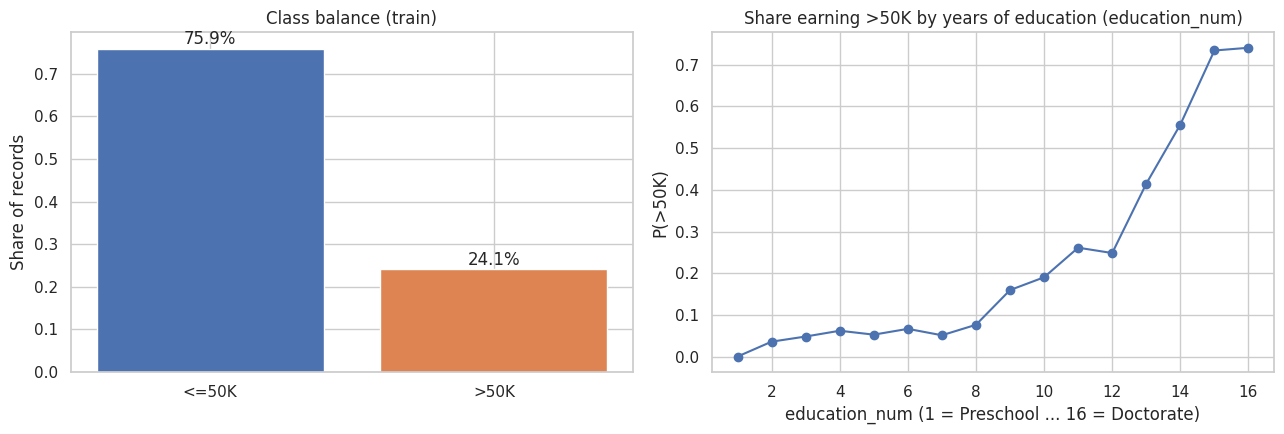

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tgt = raw_train["income"].value_counts(normalize=True)
axes[0].bar(tgt.index, tgt.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Class balance (train)"); axes[0].set_ylabel("Share of records")
for i, v in enumerate(tgt.values): axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")

edu = (raw_train.assign(high=raw_train["income"].eq(">50K"))
       .groupby("education_num")["high"].mean())
axes[1].plot(edu.index, edu.values, marker="o")
axes[1].set_title("Share earning >50K by years of education (education_num)")
axes[1].set_xlabel("education_num (1 = Preschool ... 16 = Doctorate)"); axes[1].set_ylabel("P(>50K)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_eda_balance_education.png", dpi=150); plt.show()

**Interpretation.** The target is imbalanced (about 76% `<=50K` vs 24% `>50K`), so accuracy alone is misleading: a model predicting `<=50K` for everyone would already score ~76%. We therefore report precision, recall, F1, ROC-AUC and PR-AUC throughout. The education curve is steep and almost monotonic, which is the core empirical motivation for the mission: each additional level of schooling is associated with a markedly higher probability of reaching the upper income band.

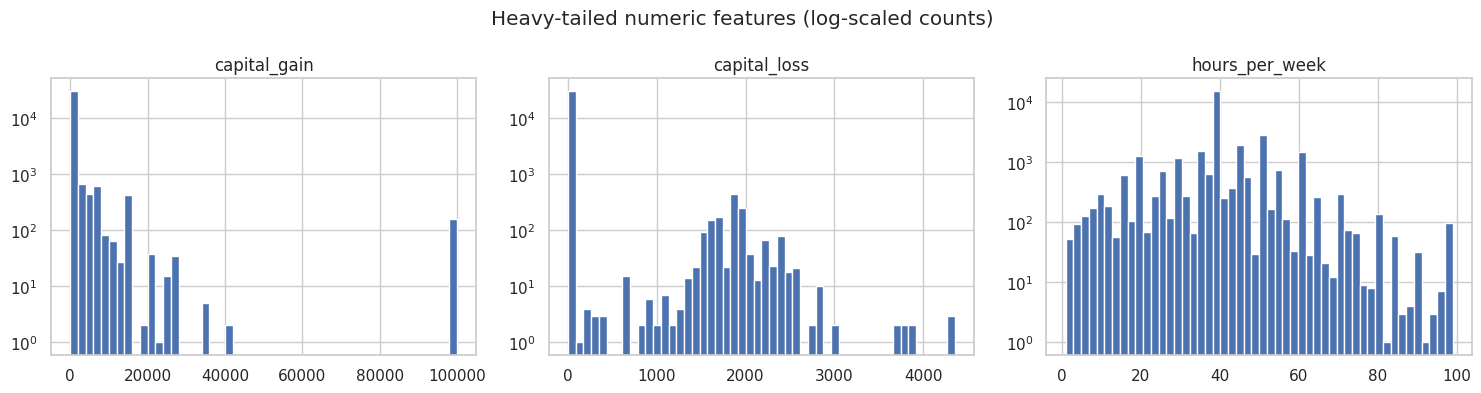

Share of zeros  - capital_gain: 91.7% | capital_loss: 95.3%
Records with capital_gain == 99999 (top-coded value): 159
education vs education_num is one-to-one: True


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["capital_gain", "capital_loss", "hours_per_week"]):
    ax.hist(raw_train[col], bins=50, color="#4C72B0")
    ax.set_title(col); ax.set_yscale("log")
plt.suptitle("Heavy-tailed numeric features (log-scaled counts)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_eda_outliers.png", dpi=150); plt.show()

print("Share of zeros  - capital_gain:", f"{(raw_train.capital_gain == 0).mean():.1%}",
      "| capital_loss:", f"{(raw_train.capital_loss == 0).mean():.1%}")
print("Records with capital_gain == 99999 (top-coded value):", (raw_train.capital_gain == 99999).sum())
print("education vs education_num is one-to-one:",
      raw_train.groupby("education")["education_num"].nunique().max() == 1)

**Interpretation.** `capital_gain` and `capital_loss` are zero for over 90% of people and extremely right-skewed; `capital_gain` is also top-coded at 99,999. These are not data-entry errors (top-coding is a census disclosure practice), so we keep the records but transform the features (log1p and binary indicators) rather than deleting them. `education` and `education_num` encode exactly the same information, so only the ordinal `education_num` is kept.

## 4. Cleaning & preprocessing
Decisions, each justified:

* **Target cleaning:** test labels carry a trailing `.` (`>50K.`); it is stripped and the target is encoded as 1 = `>50K`.
* **Missing values:** `?` appears only in `workclass`, `occupation` and `native_country`. Missingness is not random here (e.g. people with no recorded occupation are mostly outside the labour force), so it is kept as an explicit `"Unknown"` category instead of dropping ~7% of rows or imputing a mode, which would hide that signal.
* **Duplicates:** exact duplicates are removed from the training file only (never from the test set, which must stay untouched).
* **`fnlwgt`:** a census sampling weight describing how many people a record represents, not a personal characteristic. It is dropped from the predictors (its usefulness is checked empirically in E2 vs E1).
* **`education`:** dropped as redundant with `education_num`.

In [8]:
def clean(df, drop_duplicates=False):
    df = df.copy()
    df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
    df["target"] = (df["income"] == ">50K").astype(int)
    for c in ["workclass", "occupation", "native_country"]:
        df[c] = df[c].replace("?", "Unknown")
    if drop_duplicates:
        df = df.drop_duplicates()
    return df.drop(columns=["income", "education"]).reset_index(drop=True)

train_full = clean(raw_train, drop_duplicates=True)
test_df = clean(raw_test, drop_duplicates=False)
print("Train after cleaning:", train_full.shape, "| Test:", test_df.shape)
print("Positive rate - train: %.3f | test: %.3f" % (train_full.target.mean(), test_df.target.mean()))

Train after cleaning: (32537, 14) | Test: (16281, 14)
Positive rate - train: 0.241 | test: 0.236


## 5. Feature engineering
Engineered features are motivated by the EDA and by labour-economics intuition (e.g. the earnings profile over age is concave, so age² helps linear models):

| Feature | Rationale |
|---|---|
| `log_capital_gain`, `log_capital_loss` | compress extreme skew / top-coded values |
| `has_capital_gain`, `has_capital_loss` | >90% zeros: presence of investment income is itself informative |
| `age_sq` | concave age-earnings profile for linear models |
| `is_married` | merges the three "married" categories of `marital_status` (household income pooling) |
| `edu_level` | groups 16 education levels into 5 policy-relevant tiers (mission-aligned: below secondary, secondary, some tertiary, bachelor's, postgraduate) |
| `hours_band` | part-time / full-time / overtime |
| `is_us` | `native_country` is ~90% "United-States"; the 40 rare countries are summarised |

The effect of these features is measured directly (E1 vs E2), not assumed.

In [9]:
def engineer(df):
    df = df.copy()
    df["log_capital_gain"] = np.log1p(df["capital_gain"])
    df["log_capital_loss"] = np.log1p(df["capital_loss"])
    df["has_capital_gain"] = (df["capital_gain"] > 0).astype(int)
    df["has_capital_loss"] = (df["capital_loss"] > 0).astype(int)
    df["age_sq"] = df["age"] ** 2
    df["is_married"] = df["marital_status"].str.startswith("Married-civ").astype(int) | \
                       df["marital_status"].eq("Married-AF-spouse").astype(int)
    df["edu_level"] = pd.cut(df["education_num"], bins=[0, 8, 9, 12, 13, 16],
                             labels=["below_secondary", "secondary", "some_tertiary",
                                     "bachelors", "postgraduate"]).astype(str)
    df["hours_band"] = pd.cut(df["hours_per_week"], bins=[0, 34, 45, 100],
                              labels=["part_time", "full_time", "overtime"]).astype(str)
    df["is_us"] = (df["native_country"] == "United-States").astype(int)
    return df

train_full = engineer(train_full)
test_df = engineer(test_df)

BASE_NUM = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
BASE_CAT = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
ENG_NUM = ["age", "age_sq", "education_num", "log_capital_gain", "log_capital_loss",
           "has_capital_gain", "has_capital_loss", "hours_per_week", "is_married", "is_us"]
ENG_CAT = BASE_CAT + ["edu_level", "hours_band"]

train_full[ENG_NUM + ["edu_level", "hours_band"]].head()

,age,age_sq,education_num,log_capital_gain,log_capital_loss,has_capital_gain,has_capital_loss,hours_per_week,is_married,is_us,edu_level,hours_band
0,39,1521,13,7.684784,0.0,1,0,40,0,1,bachelors,full_time
1,50,2500,13,0.000000,0.0,0,0,13,1,1,bachelors,part_time
2,38,1444,9,0.000000,0.0,0,0,40,0,1,secondary,full_time
3,53,2809,7,0.000000,0.0,0,0,40,1,1,below_secondary,full_time
4,28,784,13,0.000000,0.0,0,0,40,1,0,bachelors,full_time


## 6. Data splits and preprocessing pipelines
* **Test set:** the official `adult.test` file (16,281 rows) is held out and used **once**, for the final comparison of the best ML and best DL models.
* **Train / validation:** `adult.data` is split 80/20, stratified on the target. All model selection (hyperparameters, thresholds, early stopping) uses the validation set or cross-validation on the training part only.
* **Pipelines:** scaling and one-hot encoding are fitted inside `sklearn` pipelines on the training data only, which prevents leakage into validation and test. Rare categories (<20 occurrences) are pooled by `OneHotEncoder(min_frequency=20)`, and unseen categories are ignored safely.

In [10]:
train_df, val_df = train_test_split(train_full, test_size=0.20, stratify=train_full["target"],
                                    random_state=SEED)
y_train, y_val, y_test = train_df["target"].values, val_df["target"].values, test_df["target"].values
SPLIT_DESC = f"train={len(train_df)} / val={len(val_df)} / test={len(test_df)} (stratified 80/20 + official test)"
print(SPLIT_DESC)

def make_preprocessor(num_cols, cat_cols, scale=True):
    num_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num_step, num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                              sparse_output=False), cat_cols)])

def cols(fs): return (BASE_NUM, BASE_CAT) if fs == "base" else (ENG_NUM, ENG_CAT)

train=26029 / val=6508 / test=16281 (stratified 80/20 + official test)


## 7. Evaluation and logging utilities
Every experiment goes through the same `evaluate()` function and is written to **TensorBoard** (`logs/<run_id>`), including scikit-learn runs, so the experiment table is traceable to logged runs. Open the logs with:

```
%load_ext tensorboard
%tensorboard --logdir logs
```

In [11]:
RESULTS = []

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba)}

def log_run(run_id, family, model_name, features, params, metrics, train_time, notes=""):
    # Write hyperparameters + validation metrics to TensorBoard and keep a row for the table.
    writer = tf.summary.create_file_writer(f"{LOG_DIR}/{run_id}")
    with writer.as_default():
        tf.summary.text("config", json.dumps({"model": model_name, "features": features,
                                              "split": SPLIT_DESC, **params}, default=str), step=0)
        for k, v in metrics.items():
            tf.summary.scalar(f"val/{k}", v, step=0)
    writer.flush()
    row = {"run_id": run_id, "family": family, "model": model_name, "features": features,
           "hyperparameters": json.dumps(params, default=str), **{k: round(v, 4) for k, v in metrics.items()},
           "train_time_s": round(train_time, 1), "notes": notes}
    RESULTS.append(row)
    print(f"[{run_id}] " + " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()) + f" | {train_time:.1f}s")
    return row

def run_sklearn(run_id, estimator, features="eng", scale=True, params=None, notes=""):
    set_seeds()
    num, cat = cols(features)
    pipe = Pipeline([("prep", make_preprocessor(num, cat, scale)), ("clf", estimator)])
    t0 = time.time(); pipe.fit(train_df[num + cat], y_train); t = time.time() - t0
    proba = pipe.predict_proba(val_df[num + cat])[:, 1]
    p = params or {k: v for k, v in estimator.get_params().items() if v is not None}
    log_run(run_id, "Traditional ML", type(estimator).__name__, features, p, evaluate(y_val, proba), t, notes)
    return pipe, proba

## 8. Traditional ML experiments (scikit-learn)
The experiments build on each other:

* **E1** Logistic Regression on base features (linear, interpretable baseline).
* **E2** Same model + engineered features (tests the value of feature engineering).
* **E3** E2 + `class_weight="balanced"` (tests the effect of re-weighting the minority class on recall vs precision).
* **E4** Random Forest, default settings (non-linear, captures interactions automatically).
* **E5** Random Forest tuned with `RandomizedSearchCV` (3-fold CV, ROC-AUC).
* **E6** Histogram Gradient Boosting, default settings.
* **E7** Gradient Boosting tuned with `RandomizedSearchCV`.

In [12]:
pipes, val_probas = {}, {}

pipes["E1"], val_probas["E1"] = run_sklearn("E1_logreg_base", LogisticRegression(max_iter=2000, C=1.0),
    features="base", params={"C": 1.0, "penalty": "l2", "solver": "lbfgs"},
    notes="Linear baseline on raw cleaned features")

pipes["E2"], val_probas["E2"] = run_sklearn("E2_logreg_eng", LogisticRegression(max_iter=2000, C=1.0),
    features="eng", params={"C": 1.0, "penalty": "l2", "solver": "lbfgs"},
    notes="Adds log/indicator capital features, age^2, education tiers")

pipes["E3"], val_probas["E3"] = run_sklearn("E3_logreg_eng_balanced",
    LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced"),
    features="eng", params={"C": 1.0, "class_weight": "balanced"},
    notes="Re-weights minority class")

[E1_logreg_base] accuracy=0.8560 | precision=0.7378 | recall=0.6244 | f1=0.6763 | roc_auc=0.9111 | pr_auc=0.7822 | 0.8s
[E2_logreg_eng] accuracy=0.8654 | precision=0.7598 | recall=0.6454 | f1=0.6979 | roc_auc=0.9192 | pr_auc=0.8041 | 1.3s
[E3_logreg_eng_balanced] accuracy=0.8185 | precision=0.5829 | recall=0.8673 | f1=0.6973 | roc_auc=0.9189 | pr_auc=0.8026 | 1.4s


In [13]:
pipes["E4"], val_probas["E4"] = run_sklearn("E4_rf_default",
    RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    features="eng", scale=False, params={"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1},
    notes="Fully grown trees")

[E4_rf_default] accuracy=0.8549 | precision=0.7254 | recall=0.6403 | f1=0.6802 | roc_auc=0.9003 | pr_auc=0.7655 | 4.0s


In [14]:
def tune(run_id, estimator, space, n_iter, features="eng", scale=False, notes=""):
    set_seeds()
    num, cat = cols(features)
    pipe = Pipeline([("prep", make_preprocessor(num, cat, scale)), ("clf", estimator)])
    search = RandomizedSearchCV(pipe, {f"clf__{k}": v for k, v in space.items()}, n_iter=n_iter,
                                scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                random_state=SEED, n_jobs=1)
    t0 = time.time(); search.fit(train_df[num + cat], y_train); t = time.time() - t0
    best = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    proba = search.best_estimator_.predict_proba(val_df[num + cat])[:, 1]
    log_run(run_id, "Traditional ML", type(estimator).__name__ + " (tuned)", features,
            {**best, "search": f"RandomizedSearchCV n_iter={n_iter}, 3-fold, roc_auc",
             "cv_best_auc": round(search.best_score_, 4)}, evaluate(y_val, proba), t, notes)
    return search.best_estimator_, proba, search

pipes["E5"], val_probas["E5"], rf_search = tune("E5_rf_tuned",
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 300], "max_depth": [10, 15, 20, None], "min_samples_leaf": [1, 2, 5, 10],
     "max_features": ["sqrt", 0.3, 0.5]}, n_iter=8, notes="Constrains depth/leaf size to reduce variance")

[E5_rf_tuned] accuracy=0.8702 | precision=0.7831 | recall=0.6378 | f1=0.7030 | roc_auc=0.9225 | pr_auc=0.8229 | 136.7s


In [15]:
pipes["E6"], val_probas["E6"] = run_sklearn("E6_hgb_default",
    HistGradientBoostingClassifier(random_state=SEED), features="eng", scale=False,
    params={"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31},
    notes="Boosting: sequentially corrects residual errors")

pipes["E7"], val_probas["E7"], hgb_search = tune("E7_hgb_tuned",
    HistGradientBoostingClassifier(random_state=SEED, early_stopping=True, validation_fraction=0.1),
    {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [200, 400, 600], "max_leaf_nodes": [15, 31, 63],
     "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 0.1, 1.0]},
    n_iter=12, notes="Smaller learning rate + more iterations + L2")

[E6_hgb_default] accuracy=0.8785 | precision=0.7963 | recall=0.6658 | f1=0.7253 | roc_auc=0.9327 | pr_auc=0.8428 | 1.9s
[E7_hgb_tuned] accuracy=0.8781 | precision=0.7894 | recall=0.6741 | f1=0.7272 | roc_auc=0.9328 | pr_auc=0.8427 | 131.7s


**Interpretation (E1–E7).**
* **Feature engineering helps the linear model** (E1 → E2: ROC-AUC 0.911 → 0.919, PR-AUC 0.782 → 0.804). Logistic regression cannot bend a straight line, so giving it `log_capital_gain`, the capital-gain indicator and `age_sq` hands it non-linear structure it could not learn on its own.
* **Class weighting moves the operating point, not the ranking** (E2 → E3): recall jumps 0.645 → 0.867 while precision drops 0.760 → 0.583, but ROC-AUC is unchanged (0.919). Re-weighting is equivalent to shifting the decision threshold; it does not make the model better at *separating* the classes.
* **A default Random Forest overfits** (E4 has the lowest AUC, 0.900). Fully grown trees memorise the training set (training AUC ≈ 1.0, see learning curves in Section 11). Limiting depth to 15 and leaves to ≥2 samples (E5) lifts AUC to 0.923: a classic variance reduction.
* **Gradient boosting is the strongest family** (E6/E7 ≈ 0.933). Boosting builds shallow trees sequentially, each fitting the remaining errors, which suits the threshold-like effects in this data (capital gains, marital status). Tuning (E7) gave essentially no gain over the default (0.9328 vs 0.9327) but chose a more conservative model (smaller trees, 100-sample leaves, L2 = 1.0) for the same score, which generalises more safely; it is kept as the final ML model.

## 9. Deep learning experiments (TensorFlow / Keras with `tf.data`)
Two input designs are compared:

* **One-hot MLP (Sequential API, E8–E10):** the same preprocessed matrix as the ML models, streamed through `tf.data.Dataset.from_tensor_slices(...).shuffle().batch().prefetch()`.
* **Embedding network (Functional API, E11–E13):** each categorical feature gets its own input and a learned embedding (dimension ≈ min(8, (n_categories+1)//2)), concatenated with the scaled numeric features. Embeddings let the network learn similarity between categories (e.g. related occupations) instead of treating them as unrelated one-hot columns.

All DL runs use early stopping on validation AUC (patience 5, restoring the best weights) and log epoch-level curves to TensorBoard.

In [16]:
BATCH = 256
num_e, cat_e = cols("eng")
dl_prep = make_preprocessor(num_e, cat_e, scale=True).fit(train_df[num_e + cat_e])
Xtr_oh = dl_prep.transform(train_df[num_e + cat_e]).astype("float32")
Xva_oh = dl_prep.transform(val_df[num_e + cat_e]).astype("float32")
Xte_oh = dl_prep.transform(test_df[num_e + cat_e]).astype("float32")
print("One-hot input dimension:", Xtr_oh.shape[1])

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("float32")))
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def build_mlp(input_dim, hidden=(64, 32), dropout=0.0, batchnorm=False, l2=0.0):
    reg = keras.regularizers.l2(l2) if l2 else None
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for h in hidden:
        model.add(layers.Dense(h, kernel_regularizer=reg))
        if batchnorm: model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout: model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

DL_HISTORIES, DL_MODELS = {}, {}

def run_keras(run_id, model, train_ds, val_ds, Xval, lr=1e-3, epochs=60, class_weight=None,
              reduce_lr=False, params=None, notes=""):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.AUC(curve="PR", name="pr_auc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
           keras.callbacks.TensorBoard(log_dir=f"{LOG_DIR}/{run_id}")]
    if reduce_lr:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5))
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs,
                     class_weight=class_weight, verbose=0)
    t = time.time() - t0
    proba = model.predict(Xval, batch_size=1024, verbose=0).ravel()
    p = {"lr": lr, "batch": BATCH, "epochs_run": len(hist.history["loss"]),
         "best_epoch": int(np.argmax(hist.history["val_auc"])) + 1,
         "params": model.count_params(), **(params or {})}
    log_run(run_id, "Deep Learning", params.get("arch", "MLP") if params else "MLP", "eng", p,
            evaluate(y_val, proba), t, notes)
    DL_HISTORIES[run_id], DL_MODELS[run_id] = hist.history, model
    return model, proba

One-hot input dimension: 93


In [17]:
train_ds_oh, val_ds_oh = make_ds(Xtr_oh, y_train, shuffle=True), make_ds(Xva_oh, y_val)

set_seeds()
_, val_probas["E8"] = run_keras("E8_mlp_baseline", build_mlp(Xtr_oh.shape[1], (64, 32)),
    train_ds_oh, val_ds_oh, Xva_oh, lr=1e-3,
    params={"arch": "MLP Sequential 64-32", "dropout": 0.0, "batchnorm": False},
    notes="Plain MLP, no regularisation")

set_seeds()
_, val_probas["E9"] = run_keras("E9_mlp_high_lr", build_mlp(Xtr_oh.shape[1], (64, 32)),
    train_ds_oh, val_ds_oh, Xva_oh, lr=5e-2,
    params={"arch": "MLP Sequential 64-32", "dropout": 0.0, "batchnorm": False},
    notes="Learning rate x50 to study stability")

set_seeds()
_, val_probas["E10"] = run_keras("E10_mlp_deep_reg", build_mlp(Xtr_oh.shape[1], (256, 128, 64),
    dropout=0.3, batchnorm=True, l2=1e-4), train_ds_oh, val_ds_oh, Xva_oh, lr=1e-3,
    params={"arch": "MLP Sequential 256-128-64", "dropout": 0.3, "batchnorm": True, "l2": 1e-4},
    notes="Wider/deeper + dropout, batch norm, L2")

[E8_mlp_baseline] accuracy=0.8620 | precision=0.7456 | recall=0.6486 | f1=0.6937 | roc_auc=0.9180 | pr_auc=0.7965 | 9.8s
[E9_mlp_high_lr] accuracy=0.8603 | precision=0.7216 | recall=0.6843 | f1=0.7025 | roc_auc=0.9168 | pr_auc=0.7913 | 5.1s


[E10_mlp_deep_reg] accuracy=0.8628 | precision=0.7365 | recall=0.6703 | f1=0.7018 | roc_auc=0.9204 | pr_auc=0.8051 | 23.8s


In [18]:
# ---- Functional API embedding network ----
EMB_CAT = ENG_CAT
num_scaler = StandardScaler().fit(train_df[ENG_NUM])
vocab = {c: sorted(train_df[c].unique()) for c in EMB_CAT}   # index 0 reserved for unseen

def to_inputs(df):
    d = {"numeric": num_scaler.transform(df[ENG_NUM]).astype("float32")}
    for c in EMB_CAT:
        lookup = {v: i + 1 for i, v in enumerate(vocab[c])}
        d[c] = df[c].map(lookup).fillna(0).astype("int32").values
    return d

Xtr_emb, Xva_emb, Xte_emb = to_inputs(train_df), to_inputs(val_df), to_inputs(test_df)

def make_ds_dict(Xd, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((Xd, y.astype("float32")))
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def build_embedding_net(hidden=(128, 64), dropout=0.3, l2=1e-4):
    reg = keras.regularizers.l2(l2) if l2 else None
    num_in = keras.Input(shape=(len(ENG_NUM),), name="numeric")
    inputs, parts = [num_in], [num_in]
    for c in EMB_CAT:
        n = len(vocab[c]) + 1
        inp = keras.Input(shape=(), dtype="int32", name=c)
        emb = layers.Embedding(n, min(8, (n + 1) // 2), name=f"emb_{c}")(inp)
        inputs.append(inp); parts.append(emb)
    x = layers.Concatenate()(parts)
    for h in hidden:
        x = layers.Dense(h, kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, out, name="embedding_net")

train_ds_emb, val_ds_emb = make_ds_dict(Xtr_emb, y_train, shuffle=True), make_ds_dict(Xva_emb, y_val)
pos = y_train.mean()
CW = {0: 0.5 / (1 - pos), 1: 0.5 / pos}

set_seeds()
_, val_probas["E11"] = run_keras("E11_embed_net", build_embedding_net(), train_ds_emb, val_ds_emb, Xva_emb,
    lr=1e-3, params={"arch": "Functional embeddings + 128-64", "dropout": 0.3, "l2": 1e-4},
    notes="Learned embeddings per categorical feature")

set_seeds()
_, val_probas["E12"] = run_keras("E12_embed_classweight", build_embedding_net(), train_ds_emb, val_ds_emb,
    Xva_emb, lr=1e-3, class_weight=CW,
    params={"arch": "Functional embeddings + 128-64", "dropout": 0.3, "l2": 1e-4,
            "class_weight": {k: round(v, 3) for k, v in CW.items()}},
    notes="Balanced class weights")

set_seeds()
_, val_probas["E13"] = run_keras("E13_embed_lr_schedule", build_embedding_net(), train_ds_emb, val_ds_emb,
    Xva_emb, lr=3e-3, reduce_lr=True,
    params={"arch": "Functional embeddings + 128-64", "dropout": 0.3, "l2": 1e-4,
            "schedule": "ReduceLROnPlateau x0.5, patience 2"},
    notes="Higher start LR + plateau schedule")

[E11_embed_net] accuracy=0.8636 | precision=0.7611 | recall=0.6320 | f1=0.6906 | roc_auc=0.9217 | pr_auc=0.8074 | 38.2s
[E12_embed_classweight] accuracy=0.8159 | precision=0.5771 | recall=0.8827 | f1=0.6979 | roc_auc=0.9205 | pr_auc=0.8060 | 32.5s
[E13_embed_lr_schedule] accuracy=0.8634 | precision=0.7462 | recall=0.6562 | f1=0.6983 | roc_auc=0.9208 | pr_auc=0.8071 | 15.9s


**Interpretation (E8–E13).**
* **Baseline MLP (E8)** reaches 0.918 AUC: roughly the level of the engineered logistic regression (E2, 0.919), below the tree ensembles.
* **High learning rate (E9, lr = 0.05)** is unstable: its best epoch is 6, after which validation loss climbs while training loss keeps falling, and validation AUC drops; early stopping halts it after 11 epochs. Large steps overshoot the minimum of the loss surface instead of settling into it.
* **Capacity + regularisation (E10)**: an 8× larger network (67k parameters) with dropout, batch norm and L2 gains only 0.002 AUC (0.920), so model size is not the bottleneck.
* **Embeddings (E11)** give the best DL result (0.9217 AUC) with a quarter of E10's parameters (16k). Learned dense representations of occupation, relationship and country are a more efficient way to use categorical data than one-hot columns. Because it is well regularised, it kept improving slowly for longer (best epoch 40 of 45).
* **Class weights (E12)** leave AUC essentially unchanged (0.9205) but move the operating point: recall 0.632 → 0.883, precision 0.761 → 0.577.
* **LR schedule (E13)**: starting at lr = 0.003 with `ReduceLROnPlateau` reaches almost the same AUC (0.9208) in a third of the epochs (best epoch 12 vs 40) and less than half the time (15.9 s vs 38.2 s), a speed–accuracy trade-off.
* All six DL runs sit between 0.917 and 0.922 AUC: they hit the same ceiling from different routes.

## 10. Experiment table
All metrics are on the **validation set** at the default 0.5 threshold. Each row corresponds to a TensorBoard run in `logs/<run_id>`. The table is saved to `outputs/experiment_table.csv` and is the source of the report's experiment table.

In [19]:
results_df = pd.DataFrame(RESULTS)
results_df.to_csv(f"{OUT_DIR}/experiment_table.csv", index=False)
pd.set_option("display.max_colwidth", 80)
results_df[["run_id", "family", "model", "features", "accuracy", "precision", "recall",
            "f1", "roc_auc", "pr_auc", "train_time_s", "notes"]]

,run_id,family,model,features,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s,notes
0,E1_logreg_base,Traditional ML,LogisticRegression,base,0.8560,0.7378,0.6244,0.6763,0.9111,0.7822,0.8,Linear baseline on raw cleaned features
1,E2_logreg_eng,Traditional ML,LogisticRegression,eng,0.8654,0.7598,0.6454,0.6979,0.9192,0.8041,1.3,"Adds log/indicator capital features, age^2, education tiers"
2,E3_logreg_eng_balanced,Traditional ML,LogisticRegression,eng,0.8185,0.5829,0.8673,0.6973,0.9189,0.8026,1.4,Re-weights minority class
3,E4_rf_default,Traditional ML,RandomForestClassifier,eng,0.8549,0.7254,0.6403,0.6802,0.9003,0.7655,4.0,Fully grown trees
4,E5_rf_tuned,Traditional ML,RandomForestClassifier (tuned),eng,0.8702,0.7831,0.6378,0.7030,0.9225,0.8229,136.7,Constrains depth/leaf size to reduce variance
5,E6_hgb_default,Traditional ML,HistGradientBoostingClassifier,eng,0.8785,0.7963,0.6658,0.7253,0.9327,0.8428,1.9,Boosting: sequentially corrects residual errors
6,E7_hgb_tuned,Traditional ML,HistGradientBoostingClassifier (tuned),eng,0.8781,0.7894,0.6741,0.7272,0.9328,0.8427,131.7,Smaller learning rate + more iterations + L2
7,E8_mlp_baseline,Deep Learning,MLP Sequential 64-32,eng,0.8620,0.7456,0.6486,0.6937,0.9180,0.7965,9.8,"Plain MLP, no regularisation"
8,E9_mlp_high_lr,Deep Learning,MLP Sequential 64-32,eng,0.8603,0.7216,0.6843,0.7025,0.9168,0.7913,5.1,Learning rate x50 to study stability
9,E10_mlp_deep_reg,Deep Learning,MLP Sequential 256-128-64,eng,0.8628,0.7365,0.6703,0.7018,0.9204,0.8051,23.8,"Wider/deeper + dropout, batch norm, L2"


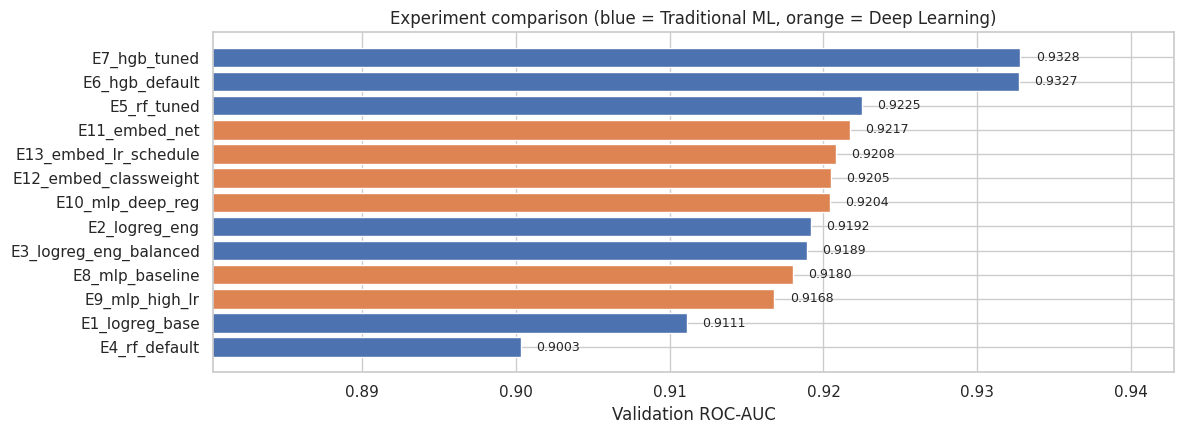

In [20]:
fig, ax = plt.subplots(figsize=(12, 4.5))
order = results_df.sort_values("roc_auc")
colors = ["#4C72B0" if f == "Traditional ML" else "#DD8452" for f in order["family"]]
ax.barh(order["run_id"], order["roc_auc"], color=colors)
ax.set_xlim(order["roc_auc"].min() - 0.02, order["roc_auc"].max() + 0.01)
ax.set_xlabel("Validation ROC-AUC"); ax.set_title("Experiment comparison (blue = Traditional ML, orange = Deep Learning)")
for i, v in enumerate(order["roc_auc"]): ax.text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_experiment_comparison.png", dpi=150); plt.show()

**Interpretation.** On validation ROC-AUC, gradient boosting (E6/E7, ≈0.933) beats every deep network (best E11, 0.922) by about 0.011, and the best network only matches the tuned Random Forest (0.9217 vs 0.9225). This mirrors the published finding that tree ensembles remain the stronger choice on medium-sized tabular data, where features are heterogeneous and individually meaningful. It also highlights a trade-off: a single boosting fit (E6) takes 1.9 s on CPU, while E11 needs about 38 s, and the boosting model is easier to explain to non-technical stakeholders.

## 11. Final evaluation on the held-out test set
The best traditional model and the best deep learning model are selected by **validation ROC-AUC** (threshold-independent). Because the classes are imbalanced, a decision threshold is then chosen on the **validation** set to maximise F1, and applied unchanged to the test set.

In [21]:
ml_ids = [r for r in val_probas if int(r[1:]) <= 7]
dl_ids = [r for r in val_probas if int(r[1:]) >= 8]
best_ml = max(ml_ids, key=lambda r: roc_auc_score(y_val, val_probas[r]))
best_dl = max(dl_ids, key=lambda r: roc_auc_score(y_val, val_probas[r]))
dl_run_name = [k for k in DL_MODELS if k.startswith(best_dl + "_")][0]
print("Best traditional ML:", best_ml, "| Best deep learning:", best_dl, f"({dl_run_name})")

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
    return float(thr[np.argmax(f1s)])

num_e, cat_e = cols("eng")
best_ml_pipe = pipes[best_ml]
best_dl_model = DL_MODELS[dl_run_name]
dl_is_embed = int(best_dl[1:]) >= 11

test_proba = {
    "ML": best_ml_pipe.predict_proba(test_df[num_e + cat_e])[:, 1],
    "DL": best_dl_model.predict(Xte_emb if dl_is_embed else Xte_oh, batch_size=1024, verbose=0).ravel()}
thresholds = {"ML": best_threshold(y_val, val_probas[best_ml]), "DL": best_threshold(y_val, val_probas[best_dl])}

rows = []
for k, name in [("ML", best_ml), ("DL", best_dl)]:
    for thr_name, thr in [("0.50", 0.5), ("F1-tuned", thresholds[k])]:
        rows.append({"model": f"{k}: {name}", "threshold": f"{thr_name} ({thr:.3f})",
                     **{m: round(v, 4) for m, v in evaluate(y_test, test_proba[k], thr).items()}})
final_df = pd.DataFrame(rows)
final_df.to_csv(f"{OUT_DIR}/final_test_results.csv", index=False)
final_df

Best traditional ML: E7 | Best deep learning: E11 (E11_embed_net)


,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,ML: E7,0.50 (0.500),0.8722,0.7727,0.6505,0.7064,0.9263,0.8236
1,ML: E7,F1-tuned (0.429),0.8681,0.7241,0.7132,0.7186,0.9263,0.8236
2,DL: E11,0.50 (0.500),0.8588,0.7474,0.6076,0.6703,0.9121,0.7811
3,DL: E11,F1-tuned (0.410),0.8534,0.6904,0.6882,0.6893,0.9121,0.7811


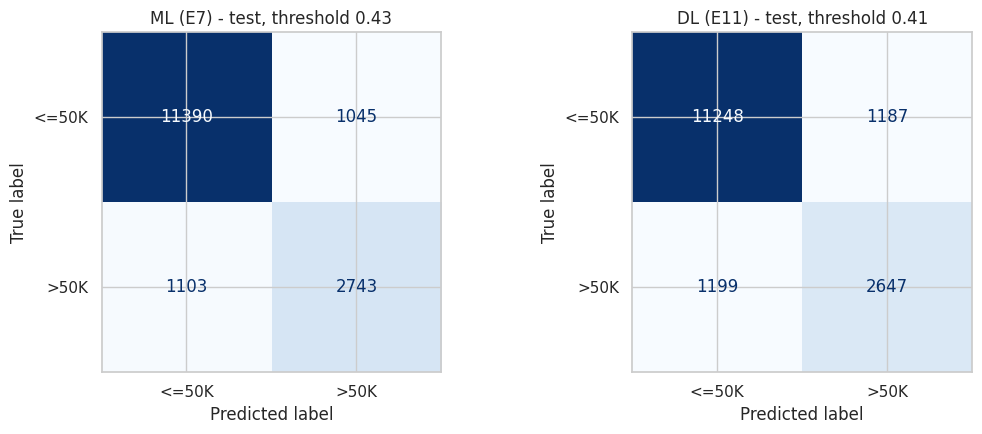

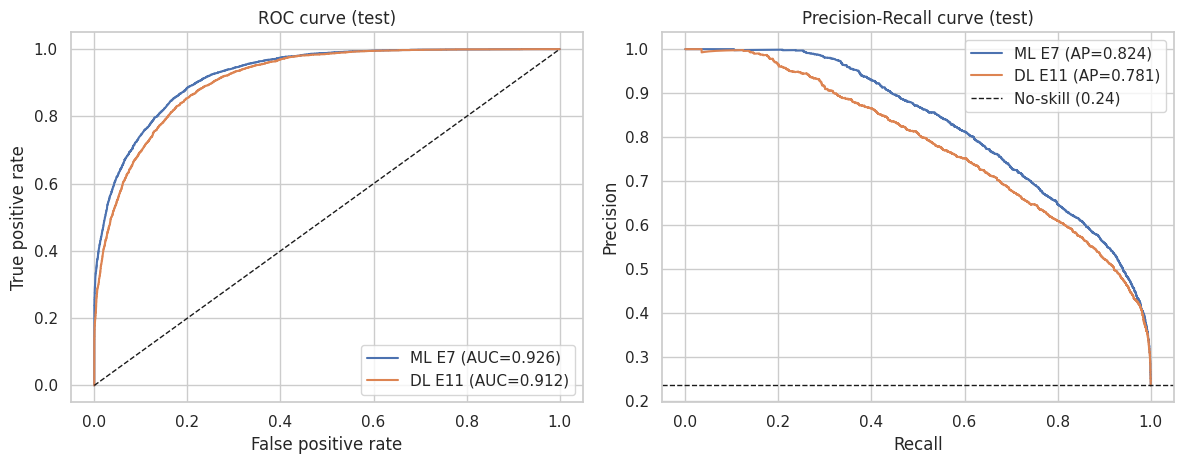

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, k, name in [(axes[0], "ML", best_ml), (axes[1], "DL", best_dl)]:
    cm = confusion_matrix(y_test, (test_proba[k] >= thresholds[k]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["<=50K", ">50K"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{k} ({name}) - test, threshold {thresholds[k]:.2f}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_confusion_matrices.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for k, name in [("ML", best_ml), ("DL", best_dl)]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[k])
    axes[0].plot(fpr, tpr, label=f"{k} {name} (AUC={roc_auc_score(y_test, test_proba[k]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, test_proba[k])
    axes[1].plot(rc, pr, label=f"{k} {name} (AP={average_precision_score(y_test, test_proba[k]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve (test)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No-skill ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curve (test)")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_roc_pr_curves.png", dpi=150); plt.show()

**Interpretation (test set, 16,281 unseen records).**
* The best ML model (E7) scores **ROC-AUC 0.926 / PR-AUC 0.824** on test vs **0.912 / 0.781** for the best DL model (E11), so the validation ranking holds on unseen data. Both lose about 0.01 AUC or less from validation (E7: 0.933 → 0.926; E11: 0.922 → 0.912), i.e. little overfitting to the validation set.
* **Thresholds:** for both models the F1-optimal threshold (chosen on validation) is below 0.5, because the minority class is under-predicted at 0.5. For E7, moving to 0.43 raises recall from 0.651 to 0.713 for a precision drop from 0.773 to 0.724 (F1 0.706 → 0.719). For E11, moving to 0.41 raises recall from 0.608 to 0.688 for a precision drop from 0.747 to 0.690 (F1 0.670 → 0.689).
* **Confusion matrices:** at the tuned thresholds both models' errors are nearly balanced: E7 makes 1,103 false negatives and 1,045 false positives; E11 makes 1,199 and 1,187. E11 misses 96 more high earners *and* raises 142 more false alarms than E7, so its lower AUC shows up as more errors of both kinds, not a different trade-off.
* **ROC vs PR:** ROC-AUC looks high partly because the large negative class makes the false-positive rate easy to keep low; the PR curve is the more honest view for the minority class, and its no-skill baseline is 0.24, not 0.5.

### Learning curves
* **Traditional ML:** `sklearn.model_selection.learning_curve` (3-fold CV ROC-AUC vs. training-set size) for the best ML model, plus the same for the default Random Forest (E4) to show the variance gap of fully grown trees.
* **Deep learning:** epoch-wise training vs validation loss and AUC for the baseline MLP (E8), the high learning-rate MLP (E9) and the best DL model.

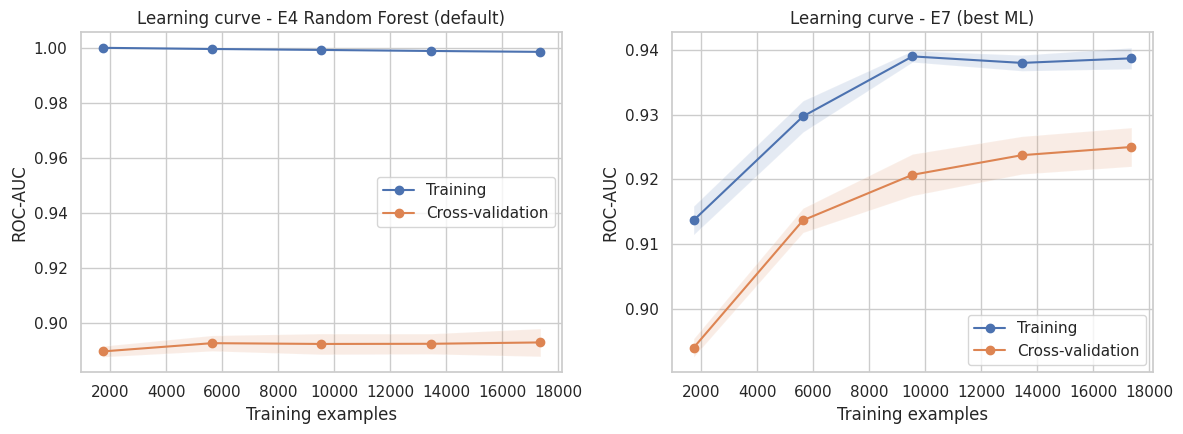

E4 final train/CV AUC: 0.998 / 0.893
E7 final train/CV AUC: 0.939 / 0.925


In [23]:
def plot_lc(ax, pipe, title):
    sizes, tr, va = learning_curve(pipe, train_df[num_e + cat_e], y_train, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                                   scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=1)
    ax.plot(sizes, tr.mean(1), "o-", label="Training"); ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=.15)
    ax.plot(sizes, va.mean(1), "o-", label="Cross-validation"); ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.15)
    ax.set_title(title); ax.set_xlabel("Training examples"); ax.set_ylabel("ROC-AUC"); ax.legend()
    return tr.mean(1)[-1], va.mean(1)[-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gap_rf = plot_lc(axes[0], pipes["E4"], "Learning curve - E4 Random Forest (default)")
gap_best = plot_lc(axes[1], best_ml_pipe, f"Learning curve - {best_ml} (best ML)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig6_learning_curves_ml.png", dpi=150); plt.show()
print("E4 final train/CV AUC: %.3f / %.3f" % gap_rf)
print(f"{best_ml} final train/CV AUC: %.3f / %.3f" % gap_best)

**Interpretation (bias–variance).** The default Random Forest (left) shows a **high-variance** pattern: training AUC ≈ 0.998 against cross-validated AUC ≈ 0.893, a gap of more than 0.10 that narrows only slowly with more data. The tuned boosting model (right) shows a gap of about 0.014 (0.939 vs 0.925) and a validation curve that has almost flattened: it is close to the bias-limited regime, so more rows of the *same* features would add little. Further gains would need new information (better features), not more capacity.

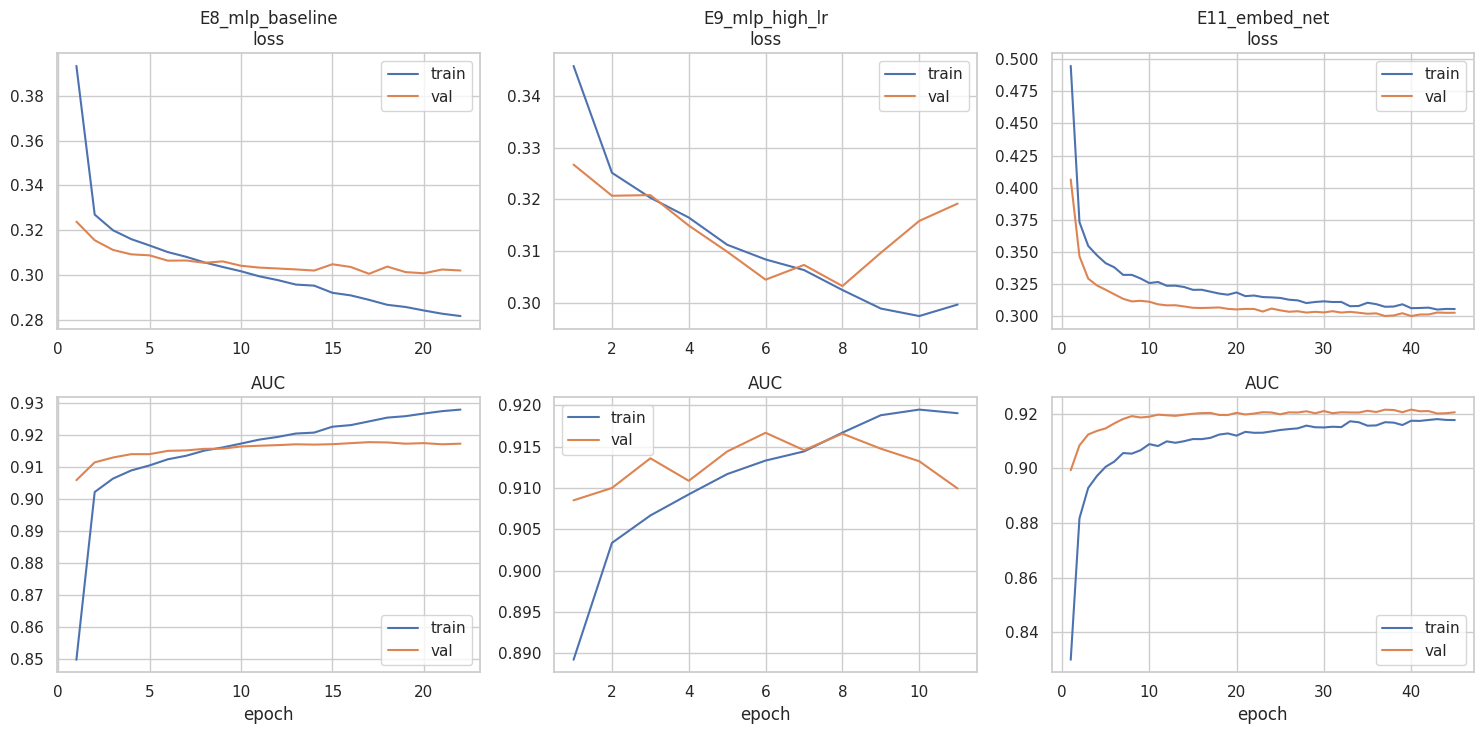

In [24]:
show = ["E8_mlp_baseline", "E9_mlp_high_lr", dl_run_name]
fig, axes = plt.subplots(2, len(show), figsize=(5 * len(show), 7.5))
for j, rid in enumerate(show):
    h = DL_HISTORIES[rid]; ep = range(1, len(h["loss"]) + 1)
    axes[0, j].plot(ep, h["loss"], label="train"); axes[0, j].plot(ep, h["val_loss"], label="val")
    axes[0, j].set_title(f"{rid}\nloss"); axes[0, j].legend()
    axes[1, j].plot(ep, h["auc"], label="train"); axes[1, j].plot(ep, h["val_auc"], label="val")
    axes[1, j].set_title("AUC"); axes[1, j].set_xlabel("epoch"); axes[1, j].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig7_learning_curves_dl.png", dpi=150); plt.show()

**Interpretation (DL learning curves).**
* **E8:** training loss keeps falling (0.39 → 0.28) while validation loss flattens around 0.30 after ~10 epochs, and training AUC overtakes validation AUC: the onset of overfitting, which early stopping caught (best epoch 17).
* **E9:** validation loss turns upward after epoch 8 and validation AUC falls from about 0.917 to 0.910 by epoch 11, the signature of an unstable learning rate.
* **E11:** validation loss stays *below* training loss for all 45 epochs (about 0.30 vs 0.305 at the end) and validation AUC stays above training AUC; the curves never diverge. Dropout (30%) and L2 are active only during training, so this indicates a well-regularised, low-variance model. Validation AUC plateaus near 0.92 after about 15 epochs: the remaining error is bias, consistent with the ceiling seen across all DL runs.

## 12. Error analysis by subgroup
For the mission, an aggregate score is not enough: we need to know **whose** outcomes the model gets wrong. We compute recall (share of true `>50K` earners found), false-positive rate and positive-prediction rate by education tier, sex and race on the test set, using the best ML model.

In [25]:
pred_ml = (test_proba["ML"] >= thresholds["ML"]).astype(int)
ea = test_df.assign(pred=pred_ml, proba=test_proba["ML"])

def group_report(df, col):
    out = []
    for g, d in df.groupby(col):
        tp = ((d.pred == 1) & (d.target == 1)).sum(); fn = ((d.pred == 0) & (d.target == 1)).sum()
        fp = ((d.pred == 1) & (d.target == 0)).sum(); tn = ((d.pred == 0) & (d.target == 0)).sum()
        out.append({col: g, "n": len(d), "actual_>50K_rate": d.target.mean(), "predicted_>50K_rate": d.pred.mean(),
                    "recall": tp / max(tp + fn, 1), "false_pos_rate": fp / max(fp + tn, 1),
                    "accuracy": (tp + tn) / len(d)})
    return pd.DataFrame(out).round(3)

edu_order = ["below_secondary", "secondary", "some_tertiary", "bachelors", "postgraduate"]
g_edu = group_report(ea, "edu_level").set_index("edu_level").loc[edu_order].reset_index()
g_sex = group_report(ea, "sex"); g_race = group_report(ea, "race")
for g in [g_edu, g_sex, g_race]: display(g)
pd.concat([g_edu.assign(group="edu_level").rename(columns={"edu_level": "value"}),
           g_sex.assign(group="sex").rename(columns={"sex": "value"}),
           g_race.assign(group="race").rename(columns={"race": "value"})]).to_csv(f"{OUT_DIR}/subgroup_errors.csv", index=False)

,edu_level,n,actual_>50K_rate,predicted_>50K_rate,recall,false_pos_rate,accuracy
0,below_secondary,2155,0.057,0.017,0.254,0.003,0.955
1,secondary,5283,0.157,0.097,0.423,0.036,0.879
2,some_tertiary,4800,0.205,0.211,0.668,0.094,0.858
3,bachelors,2670,0.409,0.479,0.872,0.208,0.825
4,postgraduate,1373,0.597,0.689,0.918,0.350,0.810


,sex,n,actual_>50K_rate,predicted_>50K_rate,recall,false_pos_rate,accuracy
0,Female,5421,0.109,0.091,0.62,0.027,0.935
1,Male,10860,0.300,0.303,0.73,0.120,0.835


,race,n,actual_>50K_rate,predicted_>50K_rate,recall,false_pos_rate,accuracy
0,Amer-Indian-Eskimo,159,0.119,0.094,0.632,0.021,0.937
1,Asian-Pac-Islander,480,0.277,0.296,0.737,0.127,0.835
2,Black,1561,0.115,0.099,0.620,0.031,0.929
3,Other,135,0.185,0.126,0.640,0.009,0.926
4,White,13946,0.250,0.248,0.718,0.091,0.861


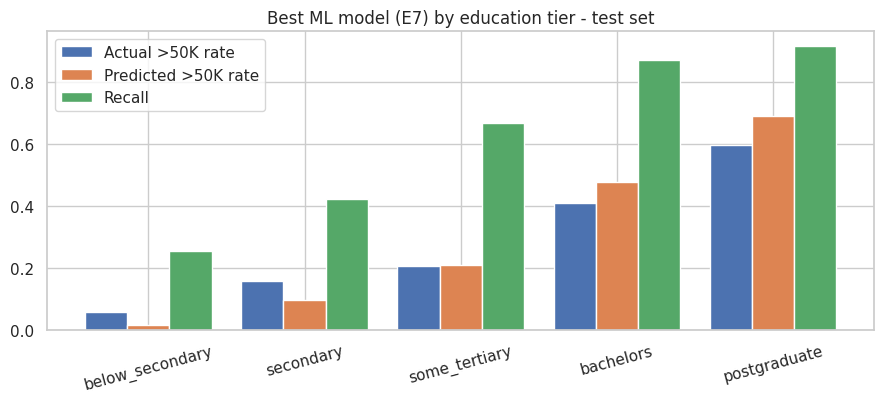

Profile of missed high earners (FN) vs correctly found high earners (TP):


,false_negatives,true_positives
age,43.19,44.78
education_num,9.97,12.23
hours_per_week,43.26,46.28
has_capital_gain,0.01,0.29
is_married,0.71,0.91


In [26]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(g_edu)); w = 0.27
ax.bar(x - w, g_edu["actual_>50K_rate"], w, label="Actual >50K rate")
ax.bar(x, g_edu["predicted_>50K_rate"], w, label="Predicted >50K rate")
ax.bar(x + w, g_edu["recall"], w, label="Recall")
ax.set_xticks(x); ax.set_xticklabels(g_edu["edu_level"], rotation=15)
ax.set_title(f"Best ML model ({best_ml}) by education tier - test set"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig8_error_by_education.png", dpi=150); plt.show()

fn = ea[(ea.target == 1) & (ea.pred == 0)]; tp = ea[(ea.target == 1) & (ea.pred == 1)]
profile = pd.DataFrame({"false_negatives": fn[["age", "education_num", "hours_per_week", "has_capital_gain", "is_married"]].mean(),
                        "true_positives": tp[["age", "education_num", "hours_per_week", "has_capital_gain", "is_married"]].mean()}).round(2)
print("Profile of missed high earners (FN) vs correctly found high earners (TP):"); profile

**Interpretation (error analysis).**
* **Education tier:** recall rises steadily with education (0.25 below secondary → 0.92 postgraduate). The model has learned that high income is rare without schooling, so it almost never predicts `>50K` for people below secondary level; the high earners it misses there are exactly the people who succeeded *despite* limited education. Conversely, false-positive rates climb with education (0.003 → 0.35): the model over-predicts high income for graduates. In other words, it amplifies the education gradient in the data.
* **Sex and race:** recall is lower for women (0.62 vs 0.73 for men) and for Black (0.62) and Amerindian (0.63) respondents than for White respondents (0.72). Part of this reflects real base-rate differences (10.9% vs 30.0% of women vs men earn >50K), which are themselves a product of structural inequality; a model trained on them reproduces them.
* **Missed high earners** have fewer years of education (10.0 vs 12.2), almost no capital gains (1% vs 29%) and are less often married (71% vs 91%) than correctly identified ones. They reach high income through routes the dominant features do not capture.
* **Mission implication:** used to target support, this model must not be used to *exclude* people with low formal education. It is better read as evidence about which barriers (education, investment income, household structure) matter most.

### Feature importance (permutation, best ML model)
Permutation importance on the validation set measures how much ROC-AUC drops when a feature is shuffled. It is model-agnostic and works on the original (pre-encoding) columns.

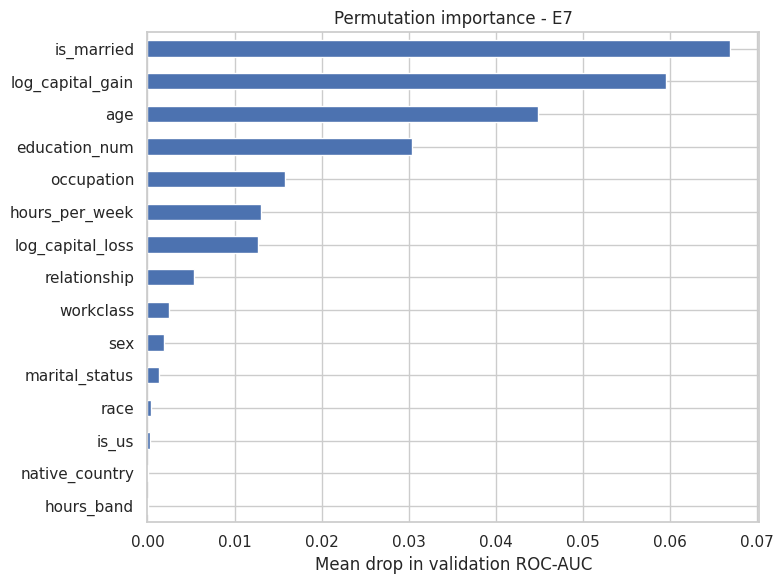

,0
is_married,0.0669
log_capital_gain,0.0596
age,0.0448
education_num,0.0303
occupation,0.0157
hours_per_week,0.0130
log_capital_loss,0.0127
relationship,0.0053
workclass,0.0025
sex,0.0019


In [27]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_ml_pipe, val_df[num_e + cat_e], y_val, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=num_e + cat_e).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
imp.tail(15).plot.barh(ax=ax, color="#4C72B0"); ax.set_xlabel("Mean drop in validation ROC-AUC")
ax.set_title(f"Permutation importance - {best_ml}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig9_permutation_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).head(10).round(4)

**Interpretation.** Marital status, capital gains, age and years of education dominate. Education ranks fourth on its own, but it also acts through occupation, which ranks fifth. For the mission, this supports interventions on two fronts: formal and adult education (education_num), and financial literacy around saving and investing (capital gains as a proxy for asset ownership).

## 13. Saving the best models
* Traditional ML: the **full scikit-learn pipeline** (preprocessing + model) is saved with `joblib`, so it can be loaded and applied directly to raw cleaned data.
* Deep learning: saved in the native Keras format (`.keras`) and in HDF5 (`.h5`). Its preprocessing objects are saved alongside it.

Upload everything in `outputs/models/` to the Google Drive folder.

In [28]:
joblib.dump(best_ml_pipe, f"{MODEL_DIR}/best_traditional_ml_{best_ml}.joblib")
best_dl_model.save(f"{MODEL_DIR}/best_deep_learning_{best_dl}.keras")
best_dl_model.save(f"{MODEL_DIR}/best_deep_learning_{best_dl}.h5")
joblib.dump({"num_scaler": num_scaler, "vocab": vocab, "dl_onehot_prep": dl_prep,
             "num_cols": ENG_NUM, "cat_cols": EMB_CAT, "thresholds": thresholds},
            f"{MODEL_DIR}/dl_preprocessing.joblib")

# Sanity check: reload and confirm identical predictions
reloaded = joblib.load(f"{MODEL_DIR}/best_traditional_ml_{best_ml}.joblib")
assert np.allclose(reloaded.predict_proba(test_df[num_e + cat_e])[:, 1], test_proba["ML"])
reloaded_dl = keras.models.load_model(f"{MODEL_DIR}/best_deep_learning_{best_dl}.keras")
assert np.allclose(reloaded_dl.predict(Xte_emb if dl_is_embed else Xte_oh, verbose=0).ravel(), test_proba["DL"], atol=1e-5)
print("Saved and verified:", os.listdir(MODEL_DIR))

Saved and verified: ['best_deep_learning_E11.keras', 'dl_preprocessing.joblib', 'best_deep_learning_E11.h5', 'best_traditional_ml_E7.joblib']


## 14. Conclusions
1. **Best model:** tuned Histogram Gradient Boosting (E7), with test ROC-AUC 0.926, PR-AUC 0.824 and F1 0.719 at a validation-tuned threshold of 0.43. The best deep network (Functional API with embeddings, E11) reached test ROC-AUC 0.912, PR-AUC 0.781 and F1 0.689.
2. **ML vs DL:** on this medium-sized, mostly categorical tabular dataset, boosting was more accurate, about 20× faster to train (1.9 s vs 38 s) and easier to interpret. Deep learning gains came from *representation* (embeddings), not from size.
3. **What moved performance:** feature engineering for linear models (+0.008 AUC), depth/leaf constraints for Random Forest (+0.022 AUC), and model family. Class weighting and threshold choice changed the precision–recall balance, not the ranking quality.
4. **Limitations:** the data is the 1994 US Census, so the income threshold, occupations and demographic structure do not represent Rwanda today; the target is a single income cut-off rather than a measure of well-being; and the models reproduce existing disparities by sex, race and education.
5. **Future work:** retrain on Rwandan microdata (e.g. NISR Labour Force Survey or EICV) with locally meaningful thresholds; add fairness constraints or group-specific thresholds; try gradient-boosting variants with monotonic constraints on education; and calibrate probabilities before using them for programme targeting.

**Reproducibility:** seed 42 everywhere; all runs logged in `logs/` (TensorBoard); results in `outputs/experiment_table.csv`; saved models in `outputs/models/`. Neural-network results can vary in the third decimal between machines; the numbers above are from the logged run in this repository.